# Плотный оптический поток Farnebäck

Используем готовый метод OpenCV: читаем поле смещений, сравниваем уровни пирамиды и применяем поток к видео. Собственной реализации плотного потока здесь нет.

In [1]:
# Графики выводятся внутри notebook.
%matplotlib inline

from pathlib import Path
import sys

# Работает при запуске из корня репозитория и из папки этого notebook.
PROJECT = Path("dense_optical_flow_lesson")
if not PROJECT.is_dir():
    PROJECT = Path("lessons/lesson_02/dense_optical_flow_lesson")
if not PROJECT.is_dir():
    PROJECT = Path(".")
sys.path.insert(0, str(PROJECT.resolve()))

import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import Video, display

from dense import farneback, flow_rgb, flow_arrows, synthetic, read_pair

# Пути отсчитываются от папки notebook.
DATA = PROJECT / "data"
OUTPUTS = PROJECT / "outputs"

## Farnebäck в OpenCV

`flow` имеет форму `(H, W, 2)`. Вектор `flow[y, x] = (u, v)` связывает точку `(x, y)` первого кадра с `(x+u, y+v)` второго. Положительные компоненты направлены вправо и вниз. Единица — пиксели за выбранную пару кадров.

Farnebäck локально приближает яркость квадратичным полиномом и оценивает смещение по изменению его коэффициентов. Наш dense LK ниже использует линейное приближение и другую систему вычислений.

`levels=1` в Farnebäck отключает дополнительные масштабы. В sparse PyrLK для этого использовался `maxLevel=0`. У плотного Farnebäck нет выходного `status`: наличие вектора не доказывает его достоверность.

Цветовой тон обозначает направление, яркость — длину вектора. `scale` — верхняя граница шкалы отображения, не параметр алгоритма. Для малого движения нужна небольшая граница, иначе поле выглядит чёрным.

Форма: (180, 240, 2) тип: float32
flow[y=90, x=120] = (u, v): [0.5023778  0.25207075]


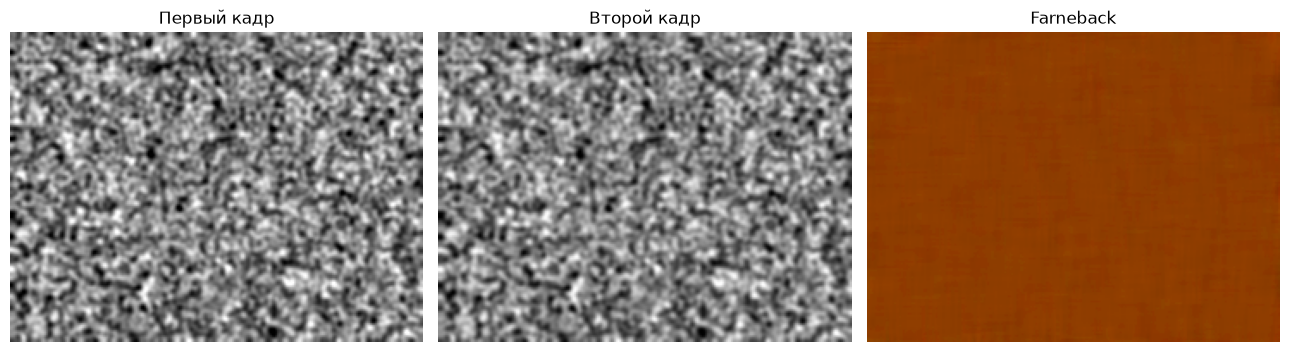

In [2]:
# Малый известный перенос: вправо на 0.5 px, вниз на 0.25 px.
previous, current = synthetic(dx=0.5, dy=0.25)
flow = cv2.calcOpticalFlowFarneback(
    previous, current, None,  # Серые uint8-кадры; массив результата создаст OpenCV.
    pyr_scale=0.5,   # Уменьшение высоты и ширины вдвое на следующем уровне.
    levels=3,       # Число уровней вместе с исходным; при 1 дополнительных нет.
    winsize=21,     # Окно усреднения: больше окно — сильнее объединяются соседние оценки.
    iterations=5,   # Число уточнений на каждом уровне, без criteria из sparse LK.
    poly_n=5,       # Размер окрестности для полиномиального приближения яркости.
    poly_sigma=1.1, # Сглаживание производных для этого приближения.
    flags=0,        # Без начального поля и флага Gaussian-усреднения.
)
print("Форма:", flow.shape, "тип:", flow.dtype)
print("flow[y=90, x=120] = (u, v):", flow[90, 120])

# Для цвета используем фиксированную шкалу 0…1 px, а не максимум этого кадра.
figure, axes = plt.subplots(1, 3, figsize=(13, 4))
images = [previous, current, flow_rgb(flow, max_motion=1)]
for axis, image, title in zip(axes, images, ["Первый кадр", "Второй кадр", "Farneback"]):
    axis.imshow(image, cmap="gray", vmin=0, vmax=255)
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

## Известный перенос

Сравним Farnebäck без пирамиды и с выбранным числом уровней. EPE — длина разности найденного и истинного векторов. Для обоих режимов берём одинаковую центральную область, исключая края.

Начните с `(0.5, 0.25)` и `scale=1`, затем поставьте `(12, 6)` и `scale=16`. Пирамида уменьшает видимое смещение на грубых уровнях. Поле есть в каждой позиции, но наличие числа не доказывает правильность.

Что удобно проверить ползунками:

| Параметр | Что меняется | Куда смотреть |
| --- | --- | --- |
| `kind` | Входная картинка: текстура, угол, граница, ровное поле | Где есть информация для поиска движения |
| `mode` | Цвет или стрелки того же поля | Направления и распределение векторов; EPE остаётся тем же |
| `scale` | Верхняя граница яркости в цветовом режиме | Цвет светлеет/темнеет; длины стрелок 1:1 не меняются |
| `window_size` | Размер окна усреднения оценок | Область хороших оценок возле угла и границы объектов |
| `levels` | Пирамида правой панели | Большой перенос `(12, 6)`; при 1 обе панели совпадают |
| `iterations` | Уточнения на каждом уровне | При большом переносе сравните 1, 5 и 10 |
| `brightness` | Яркость второго кадра | Устойчивость к изменению входа; сильное ухудшение не обязательно |

Для `kind`: поставьте `(dx, dy)=(2, 1)`, `levels=1`, `scale=4`, яркость 0. Переключите «Текстура → Ровный → Граница → Угол». На угле сравните окна 7 и 41. Область хороших оценок может вырасти, а общая медиана EPE почти не измениться: она измеряется по всей центральной области.

У ровного поля почти нулевой ответ не доказывает неподвижности: заданный перенос `(2, 1)` по однотонной картинке восстановить невозможно. Его EPE при нулевом ответе составляет примерно 2.24 px.


In [3]:
def compare_fields(previous, current, window_size=21, levels=3, iterations=5,
                   scale=8, mode="color", shift=None):
    """Вычислить и показать два режима Farnebäck с общей шкалой и областью оценки."""
    flow_one = farneback(previous, current, window_size, levels=1, iterations=iterations)
    flow_pyramid = farneback(previous, current, window_size, levels=levels, iterations=iterations)
    results = [
        ("Farneback L1", flow_one, None),
        (f"Farneback L{levels}", flow_pyramid, None),
    ]

    # Одинаковые пиксели для измерения EPE всех методов; границы исключены.
    common = np.zeros(previous.shape, dtype=bool)
    common[32:-32, 32:-32] = True
    # Layout учитывает общий заголовок и двухстрочные подписи панелей.
    figure, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
    axes[0].imshow(previous, cmap="gray", vmin=0, vmax=255)
    axes[0].set_title("Первый кадр")
    for axis, (name, flow, mask) in zip(axes.flat[1:], results):
        if mode == "color":
            image = flow_rgb(flow, max_motion=scale, valid=mask)
        else:
            drawn = flow_arrows(previous, flow, valid=mask, step=12)
            image = cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB)
        title = name
        if shift is not None:
            if common.any():
                # Ось -1 — две компоненты вектора; длина разности даёт EPE.
                error = np.linalg.norm(flow[common] - shift, axis=-1)
                title += f"\nEPE med {np.median(error):.3f}; p90 {np.percentile(error, 90):.3f} px"
            else:
                title += "\nEPE: область оценки пуста"
        axis.imshow(image)
        axis.set_title(title)
    for axis in axes.flat:
        axis.axis("off")
    if mode == "color":
        figure.suptitle(f"Общая цветовая шкала 0–{scale:g} px")
    else:
        figure.suptitle("Стрелки 1:1; шаг сетки 12 px")
    plt.show()
    plt.close(figure)  # Закрываем показанную фигуру перед следующим пересчётом.


def experiment(dx=0.5, dy=0.25, kind="texture", window_size=21,
               levels=3, iterations=5, brightness=0, scale=1, mode="color"):
    previous, current = synthetic(dx, dy, kind, brightness)
    compare_fields(previous, current, window_size, levels, iterations,
                   scale=scale, mode=mode, shift=np.array([dx, dy]))


widgets.interact(
    experiment,
    dx=widgets.FloatSlider(value=0.5, min=-16, max=16, step=0.25, continuous_update=False),
    dy=widgets.FloatSlider(value=0.25, min=-12, max=12, step=0.25, continuous_update=False),
    # kind меняет входные изображения, а не способ отрисовки.
    kind=[("Текстура", "texture"), ("Угол", "corner"), ("Граница", "edge"), ("Ровный", "flat")],
    window_size=widgets.SelectionSlider(options=[7, 15, 21, 31, 41], value=21, continuous_update=False),
    # В Farnebäck levels — число уровней; 1 означает исходную картинку без пирамиды.
    levels=widgets.IntSlider(value=3, min=1, max=5, continuous_update=False),
    # Число уточнений Farnebäck на каждом уровне.
    iterations=widgets.IntSlider(value=5, min=1, max=10, continuous_update=False),
    # Прибавка к яркости второго кадра; не путать с яркостью цветовой шкалы.
    brightness=widgets.IntSlider(value=0, min=-60, max=60, continuous_update=False),
    # Меняет только яркость отображения; одна шкала для обоих режимов.
    scale=widgets.FloatSlider(value=1, min=0.5, max=24, step=0.5, continuous_update=False),
    # Цвет и стрелки показывают одно поле; scale применяется только к цвету.
    mode=[("Цвет", "color"), ("Стрелки 1:1", "arrows")],
);

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='dx', max=16.0, min=-16.0, s…

## Видео

`gap` задаёт интервал между исходными кадрами; векторы измеряются в px за этот интервал. Для px/с нужно умножить их на `fps/gap`. В этих видео истинный поток неизвестен, поэтому EPE не вычисляем.

Для чтения направлений переключите `mode` с цвета на стрелки. Для сравнения `gap=1` и `gap=5` сохраняйте одну цветовую шкалу. Если меняете окно с 7 на 41, смотрите на границу человека и фона: более гладкая карта сама по себе не доказывает большей точности.

In [4]:
def video_experiment(clip="archery", frame=10, gap=1, window_size=21,
                     levels=3, scale=8, mode="color"):
    first, second = read_pair(DATA / f"{clip}.mp4", frame, gap)
    # BGR2GRAY даёт один канал яркости; одинаковое преобразование для обоих кадров.
    previous = cv2.cvtColor(first, cv2.COLOR_BGR2GRAY)
    current = cv2.cvtColor(second, cv2.COLOR_BGR2GRAY)
    compare_fields(previous, current, window_size, levels, scale=scale, mode=mode)


widgets.interact(
    video_experiment,
    clip=["archery", "bowling"],
    frame=widgets.IntSlider(value=10, min=0, max=60, continuous_update=False),
    gap=widgets.IntSlider(value=1, min=1, max=15, continuous_update=False),
    window_size=widgets.SelectionSlider(options=[7, 15, 21, 31, 41], value=21, continuous_update=False),
    levels=widgets.IntSlider(value=3, min=1, max=5, continuous_update=False),
    # Шкала меняет только показ, а не вычисленные векторы.
    scale=widgets.SelectionSlider(options=[2, 4, 8, 16, 32], value=8, continuous_update=False),
    mode=[("Цвет", "color"), ("Стрелки 1:1", "arrows")],
);

interactive(children=(Dropdown(description='clip', options=('archery', 'bowling'), value='archery'), IntSlider…

## Компенсация движения

Поле связывает координаты первого кадра с координатами второго. Чтобы восстановить первый кадр, в позиции `(x, y)` берём значение второго кадра из `(x+u, y+v)`. `remap` выполняет такое семплирование с интерполяцией.

Сравним фотометрический остаток до и после на одной маске. Малый остаток проверяет согласие яркостей, но не доказывает правильность движения: на плоских участках разные соответствия могут выглядеть одинаково.

Средний |остаток|: до 12.69, после 9.18 /255


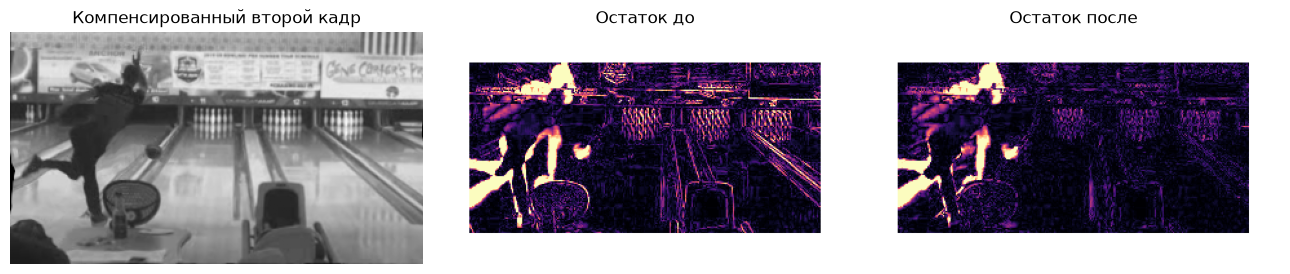

In [5]:
def warp_next(current, flow):
    """Собрать первый кадр, выбирая яркости второго по координатам x+u, y+v."""
    height, width = current.shape
    y, x = np.mgrid[:height, :width].astype(np.float32)
    map_x = x + flow[..., 0]
    map_y = y + flow[..., 1]
    inside = (
        np.isfinite(map_x) & np.isfinite(map_y)
        & (map_x >= 0) & (map_x < width - 1)
        & (map_y >= 0) & (map_y < height - 1)
    )
    warped = cv2.remap(
        current, map_x, map_y,          # Откуда брать значение для каждой выходной позиции.
        interpolation=cv2.INTER_LINEAR, # Билинейная интерполяция дробных координат.
        borderMode=cv2.BORDER_CONSTANT, # Вышедшие за кадр позиции заполняются нулями.
    )
    return warped, inside

first, second = read_pair(DATA / "bowling.mp4", frame=20, gap=5)
previous = cv2.cvtColor(first, cv2.COLOR_BGR2GRAY)
current = cv2.cvtColor(second, cv2.COLOR_BGR2GRAY)
forward = farneback(previous, current)
warped, inside = warp_next(current, forward)

# Исключаем края и выходы координат за кадр; маска общая для двух остатков.
mask = np.zeros_like(inside)
mask[24:-24, 24:-24] = inside[24:-24, 24:-24]
before = np.abs(current.astype(float) - previous)
after = np.abs(warped.astype(float) - previous)
print(f"Средний |остаток|: до {before[mask].mean():.2f}, после {after[mask].mean():.2f} /255")

figure, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(warped, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Компенсированный второй кадр")
for axis, error, title in zip(axes[1:], [before, after], ["Остаток до", "Остаток после"]):
    # np.ma.array скрывает непроверяемые пиксели; шкала ошибок одинакова.
    axis.imshow(np.ma.array(error, mask=~mask), cmap="magma", vmin=0, vmax=60)
    axis.set_title(title)
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## Видеосравнения

Четыре панели: исходный кадр, стрелки Farnebäck, цветовые поля Farnebäck без пирамиды и с ней. Шкала общая для всего ролика.

In [6]:
for path in sorted(OUTPUTS.glob("*_dense_gap5.mp4")):
    # embed=True включает видео в вывод notebook; width задаёт ширину плеера в px.
    display(Video(str(path), embed=True, width=640))

## Источники

- [Оптический поток в OpenCV](https://docs.opencv.org/4.x/d4/dee/tutorial_optical_flow.html).
- [Параметры Farnebäck](https://docs.opencv.org/4.x/dc/d6b/group__video__track.html).
- [Геометрические преобразования и remap](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html).

Далее: [FlowNetS и FlowNetC](../flownet_lesson/lesson.ipynb).